In [2]:
#Load modules
import pandas as pd
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from numpy import mean
from numpy import absolute
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV
import numpy as np


In [10]:
#pre-process the data
df = pd.read_csv("insurance.csv")

#select features
y= df['death']
X = df.drop('death',axis=1) #Select features
X = pd.get_dummies(X, drop_first=True) 

#Normalize the data
columns = X.columns #create index with column names (needed for last step)
scaler = MinMaxScaler() #initiate the scaler
X = scaler.fit_transform(X) #scale the data
X = pd.DataFrame(X,columns=columns) #turn back into a dataframe

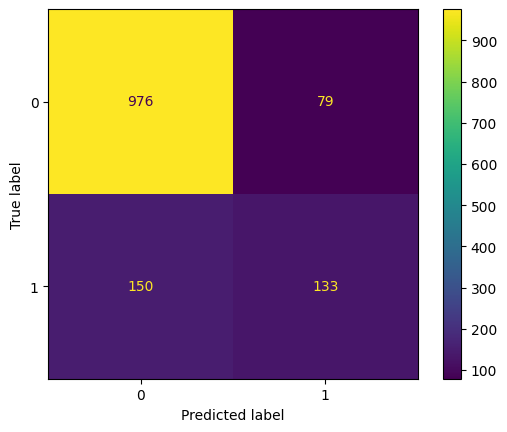

Accuracy: 0.8288490284005979


In [3]:
#Make the prediction
rf = RandomForestClassifier(n_estimators=100, random_state=69)

y_pred = cross_val_predict(rf, X, y, cv=5) #make the predictions

cm = confusion_matrix(y, y_pred) #create the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm) #create the graph
disp.plot() #plot the graph
plt.show() #show the graph

accuracy = (cm.diagonal().sum()) / cm.sum() #calculate accuracy
print("Accuracy:",accuracy) #print accuracy


In [4]:
#Calculate Gini importance
rf = RandomForestClassifier(n_estimators=100, random_state=69) #Define the model
rf.fit(X,y) #Fit the data to the random forest model
feature_importances = rf.feature_importances_ #get the GINI importances

importance_df = pd.DataFrame({ #create a dataframe shat shows the importance for each feature
    'Feature': X.columns,
    'Importance': feature_importances
})

importance_df = importance_df.sort_values(by='Importance', ascending=False) #sort the data from high to low

print(importance_df) #print the result

            Feature  Importance
1               bmi    0.391470
3           charges    0.271332
0               age    0.167591
2          children    0.061690
4          sex_male    0.030782
5        smoker_yes    0.020738
7  region_southeast    0.020283
6  region_northwest    0.019470
8  region_southwest    0.016644


In [11]:
#Hyperparameter Tuning (1)
#pre-process the data
df = pd.read_csv("insurance.csv")

y= df['charges']
X = df.drop('charges',axis=1) #Select features
X = pd.get_dummies(X, drop_first=True) 

#Normalize the data
columns = X.columns #create index with column names (needed for last step)
scaler = MinMaxScaler() #initiate the scaler
X = scaler.fit_transform(X) #scale the data
X = pd.DataFrame(X,columns=columns) #turn back into a dataframe

In [4]:
#Hyperparameter Tuning (2)
import optuna
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

# Hyperparameter tuning
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 10, 250, step=10),
        'max_depth': trial.suggest_int('max_depth', 10, 250, step=10),
        'min_samples_split': trial.suggest_int('min_samples_split', 10, 30, step=1),
        'max_features': trial.suggest_categorical('max_features', [None, 'sqrt', 'log2']),
        'random_state': 69
    }
    regressor = RandomForestRegressor(**params)
    score = cross_val_score(regressor, X, y, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1).mean()
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)  # search across 100 different combinations

print("Best params:", study.best_params)

c:\Users\Tijmen\anaconda3\envs\env2526\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-07-08 14:55:25,634] A new study created in memory with name: no-name-ffbc82f8-057f-4dba-928e-24d1f8089f84
[I 2026-07-08 14:55:29,864] Trial 0 finished with value: -2976.3703417460492 and parameters: {'n_estimators': 220, 'max_depth': 190, 'min_samples_split': 10, 'max_features': 'sqrt'}. Best is trial 0 with value: -2976.3703417460492.
[I 2026-07-08 14:55:32,598] Trial 1 finished with value: -2607.509165811461 and parameters: {'n_estimators': 130, 'max_depth': 90, 'min_samples_split': 18, 'max_features': None}. Best is trial 1 with value: -2607.509165811461.
[I 2026-07-08 14:55:33,137] Trial 2 finished with value: -2977.1060419760606 and parameters: {'n_estimators': 190, 'max_depth': 140, 'min_samples_split': 11, 'max_fe

Best params: {'n_estimators': 120, 'max_depth': 240, 'min_samples_split': 25, 'max_features': None}


In [5]:
#Run the optimized model
regressor = RandomForestRegressor(**study.best_params,
                                      random_state=69) 
RFscores = cross_val_score(regressor, X, y, cv=5,
                           scoring='neg_mean_absolute_error')
MAE = mean(absolute(RFscores))
print ('the MAE is: %.2f' % MAE)

the MAE is: 2588.83


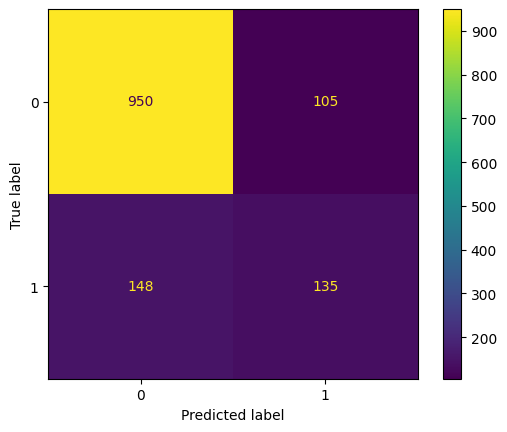

Accuracy: 0.8109118086696562


In [ ]:
#Prediction with XGBoost
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Make the prediction
xgb = XGBClassifier(n_estimators=100, random_state=69, eval_metric='logloss')
y_pred = cross_val_predict(xgb, X, y, cv=5)  # make the predictions
cm = confusion_matrix(y, y_pred)  # create the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)  # create the graph
disp.plot()  # plot the graph
plt.show()  # show the graph
accuracy = (cm.diagonal().sum()) / cm.sum()  # calculate accuracy
print("Accuracy:", accuracy)  # print accuracy

In [7]:
import optuna
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'random_state': 69,
        'eval_metric': 'logloss'
    }
    model = XGBClassifier(**params)
    score = cross_val_score(model, X, y, cv=5, scoring='accuracy').mean()
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)

print("Best params:", study.best_params)
print("Best accuracy:", study.best_value)

c:\Users\Tijmen\anaconda3\envs\env2526\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-07-02 14:39:24,620] A new study created in memory with name: no-name-75c9fc5f-ff47-465f-8159-2882561ed799
[I 2026-07-02 14:39:25,334] Trial 0 finished with value: 0.8056962379115656 and parameters: {'n_estimators': 165, 'max_depth': 7, 'learning_rate': 0.25488423993920595, 'subsample': 0.6795633512966371, 'colsample_bytree': 0.8719245540066537, 'min_child_weight': 2}. Best is trial 0 with value: 0.8056962379115656.
[I 2026-07-02 14:39:26,639] Trial 1 finished with value: 0.8243585443568673 and parameters: {'n_estimators': 485, 'max_depth': 8, 'learning_rate': 0.04748901847254695, 'subsample': 0.5236793925010714, 'colsample_bytree': 0.5924772053323033, 'min_child_weight': 2}. Best is trial 1 with value: 0.8243585443568673

Best params: {'n_estimators': 115, 'max_depth': 9, 'learning_rate': 0.020645339850686156, 'subsample': 0.6834325710726653, 'colsample_bytree': 0.6864426176892111, 'min_child_weight': 7}
Best accuracy: 0.8490273352339427


In [14]:
#Deploy the random forest model

final_model = regressor.fit(X,y) #fit the model to the entire dataset

#load in the new data and transform
new_patients = pd.read_csv('new_patients.csv')

#prepare the data
X_new = pd.get_dummies(new_patients,drop_first=True)

#Make sure it has the same columns as the data it was trained on
columns = X.columns
X_new = X_new.reindex(columns=columns, fill_value=0)

#Make sure it is transformed in the same way as the training data
X_new = scaler.transform(X_new) 

#make the predictions
predictions = final_model.predict(X_new)


c:\Users\Tijmen\anaconda3\envs\env2526\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [15]:
#print the predictions
print(predictions)

[16606.33898788  8912.49188161  7020.59744731 17432.84551181
 19601.40078411  6403.56837642 14271.060746    7306.63596213
  8655.89652161  4484.06572083]


In [13]:
#print the predictions in a cleaner table

predictions = predictions.flatten()

results_table = pd.DataFrame({
    'Patient': [f'Patient {i+1}' for i in range(len(predictions))],
    'Prediction': predictions
})

print(results_table)

      Patient    Prediction
0   Patient 1  16606.338988
1   Patient 2   8912.491882
2   Patient 3   7020.597447
3   Patient 4  17432.845512
4   Patient 5  19601.400784
5   Patient 6   6403.568376
6   Patient 7  14271.060746
7   Patient 8   7306.635962
8   Patient 9   8655.896522
9  Patient 10   4484.065721
